# Per-puzzle (dynamic) graphs in PyNeuraLogic

The best model uses one padded graph for every puzzle (16 panels x 9 slots, empty slots = `absent`),
because the torch wrapper grounds a single network once. Native PyNeuraLogic grounds every sample from
its own facts against one template, so the graph can follow the puzzle: one node per object that is
actually there, plus one node per panel. Code: `pynl/dynamic_graph.py`.

Puzzles here come from `pynl/mini_raven.py`, a small synthetic I-RAVEN-like generator (2x2 and 3x3
grids), not from I-RAVEN.

In [1]:
import os, sys, inspect, json, glob
import numpy as np
import matplotlib.pyplot as plt
import neuralogic
neuralogic.set_max_memory_size(4)
from neuralogic.logging import clear_handlers
clear_handlers()
if os.path.basename(os.getcwd()) == "notebooks": os.chdir("..")
sys.path[:0] = [os.path.abspath("."), os.path.abspath("pynl")]

from neuralogic.core import R, Settings
from neuralogic.dataset import Dataset, Sample
from neuralogic.nn.loss import CrossEntropy
from neuralogic.nn import Adam
import dynamic_graph as dg, graph_viz as gv, mini_raven as mr

puzzles = mr.dataset(300, 1)
pz = next(p for p in puzzles if p["grid"] == "3x3" and p["layout_rule"] == "num_prog")

## 1. A puzzle
8 context panels (the 3x3 matrix without its last cell) and 8 candidates; the answer is framed green.

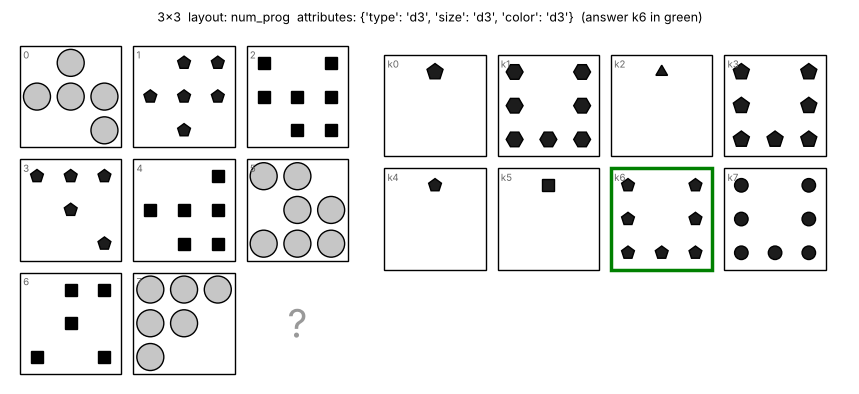

In [2]:
gv.draw_puzzle(pz); plt.show()

## 2. Facts: one set per puzzle
Every object becomes a node `o{panel}_{position}` with five one-hot facts (type, size, colour, position,
panel role; all candidates share role 8). A one-hot fact times a `[d, n]` rule weight is an embedding
lookup, so the torch tables move into the template. Edges are only generated where objects exist.

In [3]:
print(inspect.getsource(dg.facts_dynamic))

def facts_dynamic(pz):
    f = []
    where = defaultdict(list)                            # position -> [(panel, node)]
    for p, objs in enumerate(pz["panels"]):
        for o in objs:
            n = f"o{p}_{o['pos']}"
            f += obj_facts(n, o, p)
            f.append(R.in_panel(n, f"q{p}"))
            where[o["pos"]].append((p, n))
    for occ in where.values():
        for i, a in occ:
            for j, b in occ:
                if connected(i, j):
                    f.append(R.edge(a, b, pedge_type(i, j)))
    return f + panel_facts()



In [4]:
facts = dg.facts_dynamic(pz)
for f in facts[:6]: print(f)
print()
print(dict(gv.fact_counts(facts)))

[0.0, 0.0, 0.0, 0.0, 1.0] ty(o0_5).
[0.0, 0.0, 0.0, 0.0, 1.0, 0.0] sz(o0_5).
[0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0] co(o0_5).
[0.0, 0.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0] ps(o0_5).
[1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0] rl(o0_5).
in_panel(o0_5, q0).

{'ty': 79, 'sz': 79, 'co': 79, 'ps': 79, 'rl': 79, 'in_panel': 79, 'edge': 528, 'ctx_panel': 8, 'cand_panel': 8, 'pedge': 184}


## 3. Object level
`edge(a, b, t)` links two objects at the same position in two different panels (never two
candidates); `t` says whether the panels share a row, a column, or neither, and whether a candidate is
involved. A position that is empty in one panel simply has no edge there.

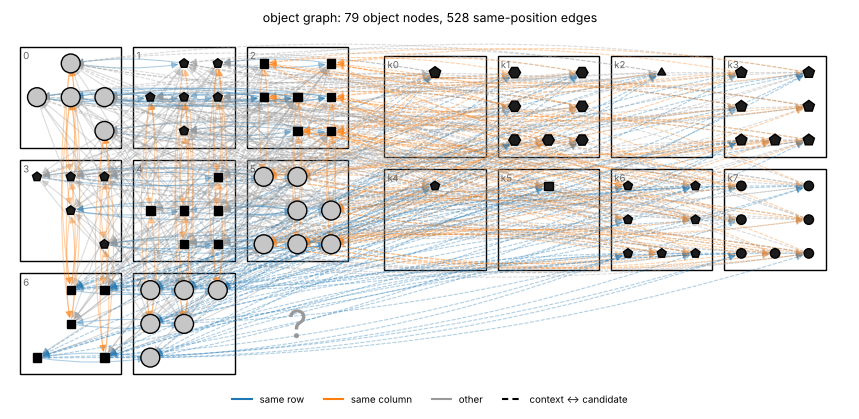

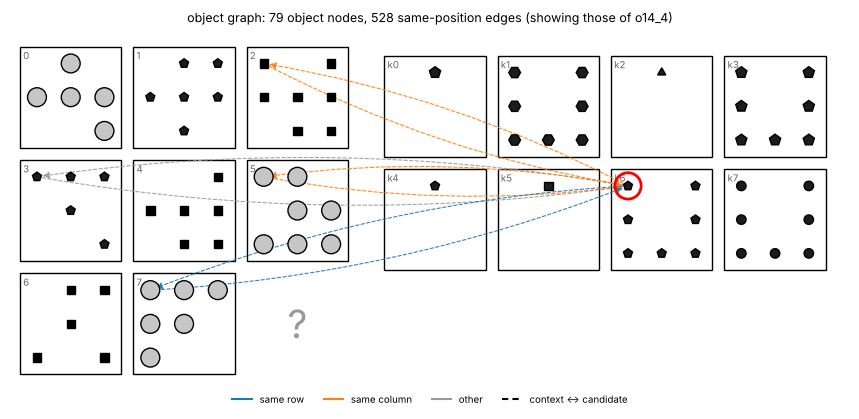

In [5]:
gv.draw_object_graph(pz, facts); plt.show()
focus = f"o{8 + pz['target']}_{pz['panels'][8 + pz['target']][0]['pos']}"
gv.draw_object_graph(pz, facts, focus=focus); plt.show()

## 4. Panel level
Each panel gets a node `q{p}`. Objects feed their panel with SUM, so the panel vector is a sum over
the objects present (it carries the count and the set of positions); panels exchange messages labelled
by row / column, and send their vector back down to their objects.

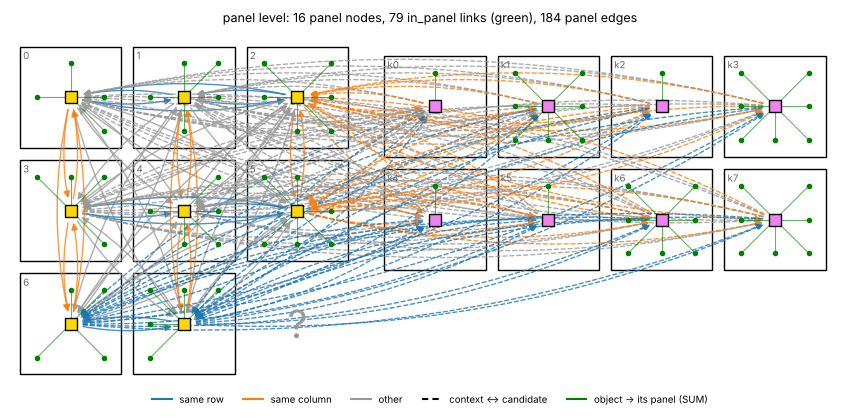

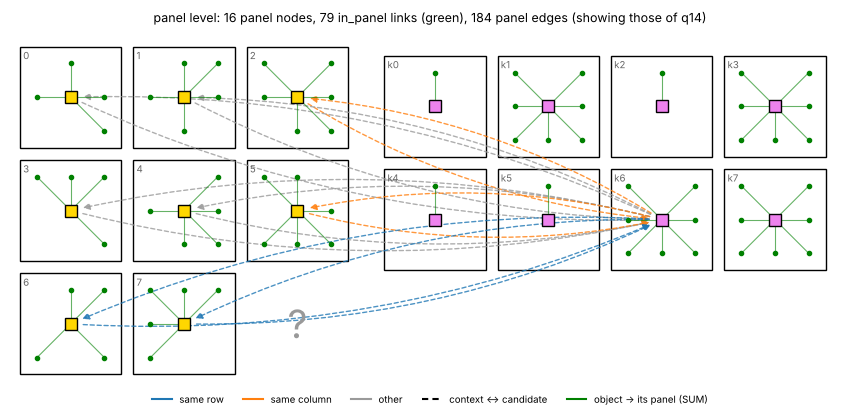

In [6]:
gv.draw_panel_graph(pz, facts); plt.show()
gv.draw_panel_graph(pz, facts, focus=f"q{8 + pz['target']}"); plt.show()

## 5. Fixed vs per-puzzle graph for the same puzzle

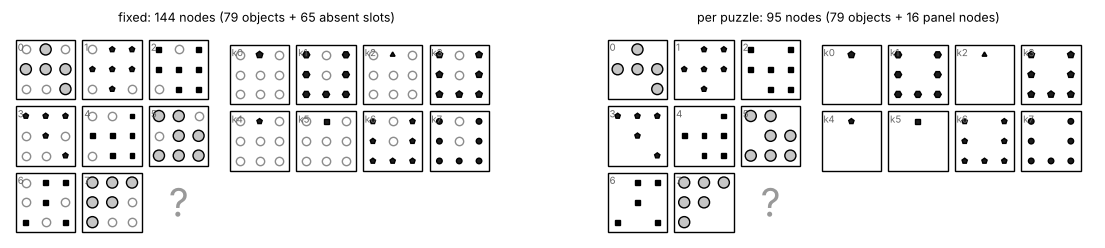

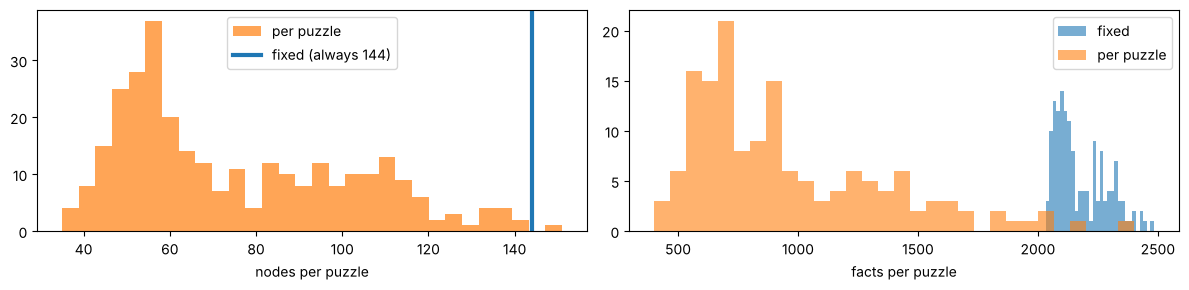

In [7]:
gv.draw_fixed_vs_dynamic(pz, mr.GRIDS[pz["grid"]], mr._geometry); plt.show()

def n_nodes(p, mode):
    return 16 * dg.SLOTS if mode == "fixed" else sum(map(len, p["panels"])) + 16
fig, axs = plt.subplots(1, 2, figsize=(12, 3))
axs[0].hist([n_nodes(p, "dynamic") for p in puzzles], bins=30, color="C1", alpha=0.7, label="per puzzle")
axs[0].axvline(16 * dg.SLOTS, color="C0", lw=3, label="fixed (always 144)")
for mode, build in [("fixed", dg.facts_fixed), ("per puzzle", dg.facts_dynamic)]:
    axs[1].hist([len(build(p)) for p in puzzles[:150]], bins=30, alpha=0.6, label=mode)
axs[0].set_xlabel("nodes per puzzle"); axs[1].set_xlabel("facts per puzzle"); axs[1].legend()
axs[0].legend(); plt.tight_layout(); plt.show()

## 6. Template
One template for all puzzles. `h*` are object vectors, `g*` panel vectors; the head scores each
candidate panel against the average context panel. The CONCAT-order probe (`cidx`) is copied
from `pynl_symbolic.py`. The last object layer (`h2`) feeds nothing here, so the grounder prunes it.

In [8]:
print(dg.template("dynamic", 32, 2))

{32} edge_emb(cc).
{32} pedge_emb(cc).
{32} edge_emb(cc_row).
{32} pedge_emb(cc_row).
{32} edge_emb(cc_col).
{32} pedge_emb(cc_col).
{32} edge_emb(cx).
{32} pedge_emb(cx).
{32} edge_emb(cx_row).
{32} pedge_emb(cx_row).
{32} edge_emb(cx_col).
{32} pedge_emb(cx_col).
{32} edge_emb(xc).
{32} pedge_emb(xc).
{32} edge_emb(xc_row).
{32} pedge_emb(xc_row).
{32} edge_emb(xc_col).
{32} pedge_emb(xc_col).
h0(O) :- {32, 5} ty(O), {32, 6} sz(O), {32, 10} co(O), {32, 13} ps(O), {32, 9} rl(O).
h0/1 [transformation=identity]
g0(P) :- in_panel(O, P), {32, 32} h0(O). [aggregation=sum]
g0/1 [transformation=norm]
h1(D) :- edge(S, D, T), {32, 32} h0(S), edge_emb(T). [aggregation=avg]
h1(X) :- h0(X).
g1(D) :- pedge(S, D, T), {32, 32} g0(S), pedge_emb(T). [aggregation=avg]
g1(X) :- g0(X).
g1(P) :- in_panel(O, P), {32, 32} h0(O). [aggregation=sum]
h1(O) :- in_panel(O, P), {32, 32} g0(P).
g1/1 [transformation=norm]
h1/1 [transformation=norm]
h2(D) :- edge(S, D, T), {32, 32} h1(S), edge_emb(T). [aggregation=av

## 7. Grounding
`build_dataset` grounds each puzzle into its own network. Atom neurons per predicate for this puzzle
(per layer: one per object `h`, one per panel `g`), fixed vs per-puzzle:

In [9]:
def ground(mode, ps):
    m = dg.template(mode, 32, 2)
    m.build(Settings(optimizer=Adam(lr=1e-3), error_function=CrossEntropy(with_logits=True),
                     iso_value_compression=False))
    build = dg.facts_fixed if mode == "fixed" else dg.facts_dynamic
    s = [Sample(R.answer(f"g{i}")[[0.0] * 8], [R.puzzle(f"g{i}")] + build(p)) for i, p in enumerate(ps)]
    return m, list(m.build_dataset(Dataset(s)))

atoms = {}
for mode in ["fixed", "dynamic"]:
    m, (b,) = ground(mode, [pz])
    atoms[mode] = {k: len(v) for k, v in b.neurons["AtomNeuron"].items()}
    print(f"{mode:8s}", atoms[mode])
    scores = np.asarray(list(m.test([b]))[0], dtype=float).flatten()
    print(f"{'':8s} untrained scores (CONCAT order):", np.round(scores, 2))

fixed    {'h1': 144, 'h2': 144, 'answer': 1}
         untrained scores (CONCAT order): [-0.28 -0.2  -0.39 -0.38 -0.3  -0.35 -0.27 -0.23]


dynamic  {'g1': 16, 'h1': 79, 'g2': 16, 'answer': 1}
         untrained scores (CONCAT order): [2.92 2.33 2.86 2.68 2.8  1.97 2.54 2.13]


## 8. Prototype training runs
2,000 train / 300 val synthetic puzzles, d = 32, 2 layers, Adam lr 3e-3, 15 epochs, one seed each,
chance 12.5%. Both arms use the same edge labels and head; `fixed` is today's structure trained natively.

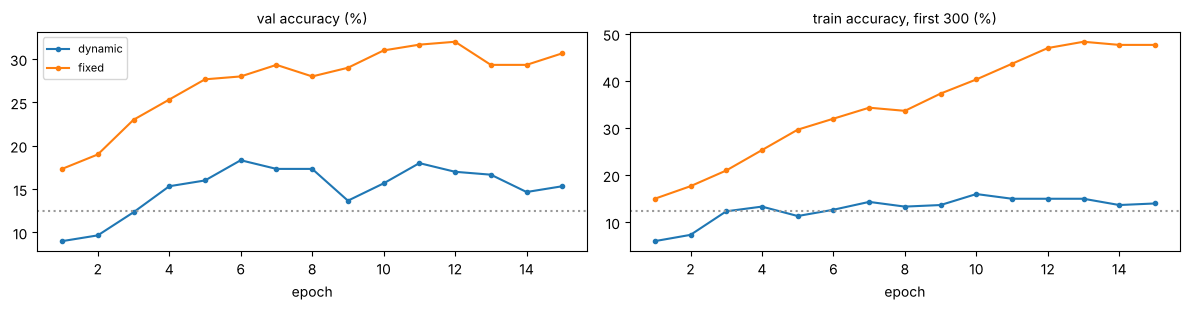

In [10]:
fig, axs = plt.subplots(1, 2, figsize=(12, 3.2))
for f in sorted(glob.glob("notebooks/dynamic_graph_runs/*.json")):
    h = json.load(open(f))["history"]
    name = os.path.basename(f)[:-5]
    ep = [r["epoch"] for r in h]
    axs[0].plot(ep, [100 * r["val"]["all"] for r in h], marker="o", ms=3, label=name)
    axs[1].plot(ep, [100 * r["train"] for r in h], marker="o", ms=3, label=name)
for ax, t in zip(axs, ["val accuracy (%)", "train accuracy, first 300 (%)"]):
    ax.axhline(12.5, color="0.6", ls=":"); ax.set_xlabel("epoch"); ax.set_title(t, fontsize=10)
axs[0].legend(fontsize=8); plt.tight_layout(); plt.show()